# Proyecto de aula - Minería de Datos | Segundo avance (corte 2)
## Predicción de accidente cerebrovascular mediante técnicas de minería de datos basadas en variables clínicas, demográficas y de estilo de vida

**Tipo de proyecto:** Clasificación binaria (`stroke`: 0 = no, 1 = sí).  
**Integrantes:** Adrián Garcia De la Rosa; Camilo Cornado Barraza; Liann Rivero Torres; Santiago García Jiménez.  
**Docente:** José Escorcia Gutiérrez · **Grupo:** 25786 · **Universidad de la Costa** · **21 de octubre de 2026**.

**Pregunta de investigación:** ¿En qué medida modelos de clasificación pueden identificar registros de accidente cerebrovascular a partir de variables clínicas, demográficas y de estilo de vida?  
**Procedencia:** Continuación del avance 1; se conservan su descripción, diagnóstico de calidad, decisiones de limpieza y EDA, complementados con exploración adicional, modelado y evaluación.  
**Alcance:** ejercicio académico de minería de datos; *no es una herramienta de diagnóstico médico*.

## 1. Descripción del conjunto de datos

El conjunto de datos utilizado corresponde al **Stroke Prediction Dataset**, obtenido de Kaggle. Contiene información clínica, demográfica y relacionada con el estilo de vida de diferentes personas.

El dataset original está compuesto por **5.110 registros y 12 variables**. La variable objetivo es `stroke`, que indica si una persona presentó (`1`) o no presentó (`0`) un accidente cerebrovascular.

Entre las variables disponibles se encuentran edad, género, hipertensión, enfermedad cardíaca, nivel promedio de glucosa, índice de masa corporal, tipo de trabajo, tipo de residencia y condición frente al consumo de tabaco.

**Nombre del dataset:** Stroke Prediction Dataset

**Fuente:** Kaggle

**Enlace:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

**Archivo utilizado:** healthcare-dataset-stroke-data.csv

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
pd.set_option('display.max_columns', None)
plt.rcParams.update({'figure.dpi': 115, 'axes.titlesize': 12, 'axes.labelsize': 10})

In [2]:
# Lectura portable: funciona en Jupyter local o en Colab si el CSV está cargado.
# El CSV de la entrega debe ubicarse en la misma carpeta que este notebook.
rutas = [Path('healthcare-dataset-stroke-data.csv'),
         Path('healthcare-dataset-stroke-data (1).csv')]
ruta_csv = next((r for r in rutas if r.is_file()), None)
if ruta_csv is None:
    raise FileNotFoundError('No se encontró el CSV. Ubícalo junto al notebook como healthcare-dataset-stroke-data.csv')
print('Dataset:', ruta_csv)


Dataset: healthcare-dataset-stroke-data.csv


In [3]:
df = pd.read_csv(ruta_csv)
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
df.shape

(5110, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


## 2. Descripción de las variables

El conjunto de datos contiene 12 variables. Estas incluyen características demográficas, clínicas y relacionadas con el estilo de vida, además de la variable objetivo `stroke`.
| Variable            | Tipo               | Descripción                                                   |
| ------------------- | ------------------ | ------------------------------------------------------------- |
| `id`                | Numérica           | Identificador único de cada registro.                         |
| `gender`            | Categórica         | Género de la persona: Male, Female u Other.                   |
| `age`               | Numérica           | Edad de la persona.                                           |
| `hypertension`      | Binaria            | Indica si presenta hipertensión: 0 = No, 1 = Sí.              |
| `heart_disease`     | Binaria            | Indica si presenta enfermedad cardíaca: 0 = No, 1 = Sí.       |
| `ever_married`      | Categórica         | Indica si la persona ha estado casada: Yes o No.              |
| `work_type`         | Categórica         | Tipo de trabajo de la persona.                                |
| `Residence_type`    | Categórica         | Tipo de residencia: Urban o Rural.                            |
| `avg_glucose_level` | Numérica           | Nivel promedio de glucosa.                                    |
| `bmi`               | Numérica           | Índice de masa corporal.                                      |
| `smoking_status`    | Categórica         | Estado relacionado con el consumo de tabaco.                  |
| `stroke`            | Binaria / objetivo | Indica si presentó accidente cerebrovascular: 0 = No, 1 = Sí. |


## 3. Diagnóstico inicial de calidad de los datos

Se realizó una revisión inicial del conjunto de datos con el fin de identificar valores faltantes, registros duplicados, categorías poco frecuentes y posibles problemas de calidad que pudieran afectar las etapas posteriores del análisis.

El diagnóstico permitió identificar los siguientes aspectos:

- El dataset original contiene 5.110 registros y 12 variables.
- La variable `bmi` presenta 201 valores faltantes.
- No se encontraron registros duplicados.
- La variable `gender` contiene una categoría `Other` con un solo registro.
- La variable `smoking_status` contiene 1.544 registros con la categoría `Unknown`.
- La variable objetivo `stroke` presenta un fuerte desbalance de clases:
  - 4.861 registros con `stroke = 0`.
  - 249 registros con `stroke = 1`.
  - Aproximadamente 95,13 % de los registros pertenecen a la clase 0 y 4,87 % a la clase 1.

El desbalance de la variable objetivo deberá ser tenido en cuenta en las siguientes etapas del proyecto, especialmente durante el entrenamiento y evaluación de los modelos de clasificación.

In [6]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
for col in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


gender:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

ever_married:
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

work_type:
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Residence_type:
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

smoking_status:
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


In [9]:
df['stroke'].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [10]:
df['stroke'].value_counts(normalize=True) * 100

stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64

### Observaciones del diagnóstico

El principal problema identificado en la calidad del conjunto de datos corresponde a los valores faltantes de la variable `bmi`.

También se identificó una categoría poco frecuente en `gender`, denominada `Other`, con un único registro. Por otra parte, la categoría `Unknown` de `smoking_status` se conserva inicialmente, debido a que representa una cantidad considerable de registros y no puede asumirse automáticamente como un valor nulo.

La variable objetivo presenta un desbalance considerable, por lo cual en etapas posteriores será necesario utilizar métricas adicionales al accuracy, como precision, recall, F1-score y matriz de confusión.

## 4. Limpieza inicial de los datos

A partir del diagnóstico de calidad se realizaron algunos ajustes iniciales sobre el conjunto de datos.

En primer lugar, los 201 valores faltantes de la variable `bmi` fueron imputados utilizando la mediana de la variable. Se escogió la mediana porque el BMI presenta valores extremos y esta medida es menos sensible a ellos que la media.

También se eliminó el único registro correspondiente a la categoría `Other` de la variable `gender`, debido a que representaba una sola observación dentro de un conjunto de 5.110 registros.

Por último, se eliminó la variable `id`, ya que funciona únicamente como identificador de cada registro y no representa una característica clínica, demográfica o de estilo de vida útil para el análisis predictivo.

**Nota metodológica del segundo corte:** la imputación realizada aquí es exclusivamente para el EDA descriptivo y conserva el procedimiento del primer avance. En la sección de modelos se vuelve a leer el CSV sin imputaciones previas y la mediana se aprende **solo con el conjunto de entrenamiento** dentro de un `Pipeline`, evitando filtración de información hacia la prueba.

In [11]:
df['bmi'].median()

np.float64(28.1)

In [12]:
df['bmi'].mean()

np.float64(28.893236911794666)

In [13]:
df['bmi'] = df['bmi'].fillna(df['bmi'].median())

In [14]:
df['bmi'].isnull().sum()

np.int64(0)

In [15]:
df[df['gender'] == 'Other']

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
3116,56156,Other,26.0,0,0,No,Private,Rural,143.33,22.4,formerly smoked,0


In [16]:
df = df[df['gender'] != 'Other']

In [17]:
df['gender'].value_counts()

gender
Female    2994
Male      2115
Name: count, dtype: int64

In [18]:
df = df.drop(columns=['id'])

In [19]:
df.shape

(5109, 11)

In [20]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [21]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


### Resultado de la limpieza inicial

Después de la limpieza inicial, el conjunto de datos quedó compuesto por **5.109 registros y 11 variables**.

No quedaron valores faltantes en las variables analizadas y se eliminó la columna `id`. La categoría `Unknown` de `smoking_status` se conservó, ya que representa una cantidad importante de registros y no existe evidencia suficiente para considerarla un error o reemplazarla en esta etapa.

Los 5.109 registros se utilizarán para el EDA. Para entrenar y evaluar los modelos se recuperan los 201 valores faltantes originales en `bmi`, de forma que el ajuste de la imputación ocurra exclusivamente en entrenamiento.

## 5. Primeras visualizaciones y análisis exploratorio inicial

Con el propósito de conocer mejor el comportamiento de las variables y explorar posibles relaciones con la variable objetivo `stroke`, se realizaron varias visualizaciones iniciales.

Estas gráficas permiten observar la distribución de la variable objetivo, la edad, el nivel promedio de glucosa, el índice de masa corporal y algunas variables categóricas relacionadas con la presencia o ausencia de accidente cerebrovascular.

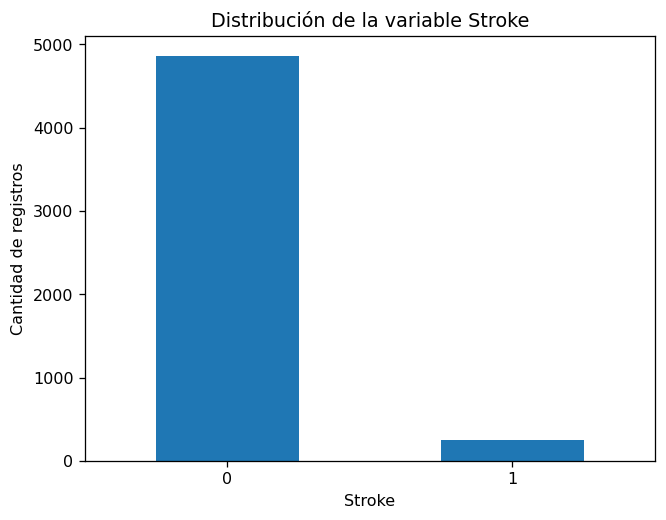

In [22]:
df['stroke'].value_counts().plot(kind='bar')

plt.title('Distribución de la variable Stroke')
plt.xlabel('Stroke')
plt.ylabel('Cantidad de registros')
plt.xticks(rotation=0)
plt.show()

### 5.1 Distribución de la variable objetivo

La variable `stroke` presenta un fuerte desbalance. La clase 0 concentra la mayoría de los registros, mientras que la clase 1 representa una proporción considerablemente menor.

Este comportamiento deberá tenerse en cuenta en las etapas posteriores de modelado y evaluación.

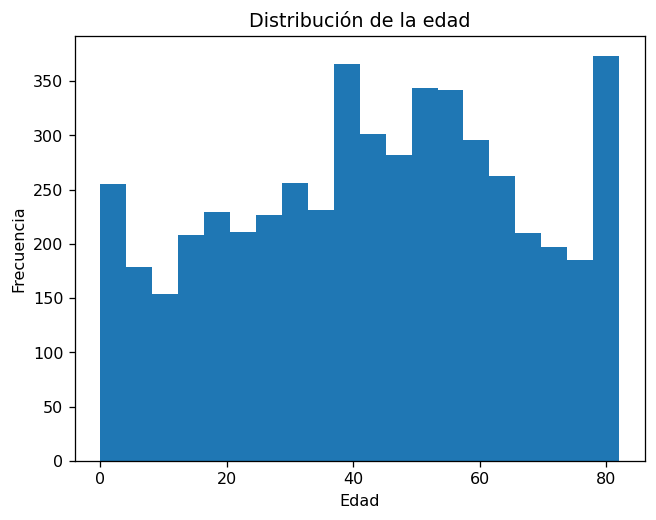

In [23]:
df['age'].plot(kind='hist', bins=20)

plt.title('Distribución de la edad')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

### 5.2 Distribución de la edad

El conjunto de datos incluye personas de diferentes edades, desde edades muy tempranas hasta aproximadamente 82 años. La distribución muestra presencia de registros a lo largo de gran parte del rango de edad.

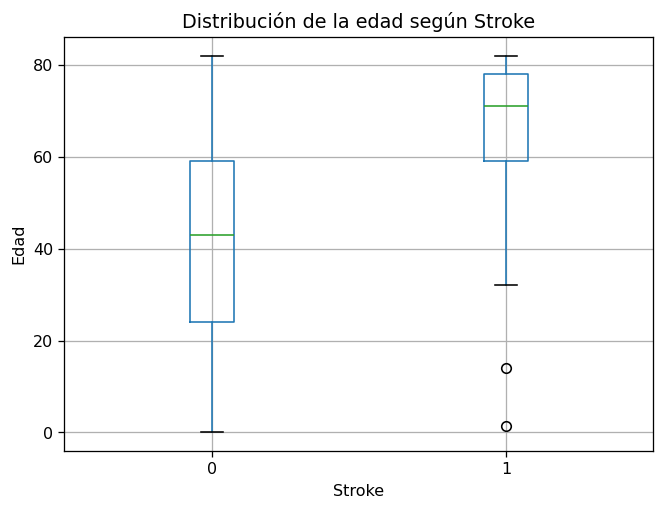

In [24]:
df.boxplot(column='age', by='stroke')

plt.title('Distribución de la edad según Stroke')
plt.suptitle('')
plt.xlabel('Stroke')
plt.ylabel('Edad')
plt.show()

### 5.3 Edad según ocurrencia de Stroke

Se observa que las personas con `stroke = 1` presentan, en general, edades más altas que aquellas con `stroke = 0`.

Esta observación sugiere una posible relación entre la edad y la ocurrencia de accidente cerebrovascular dentro del conjunto de datos, aunque esta relación deberá analizarse con mayor profundidad en etapas posteriores.

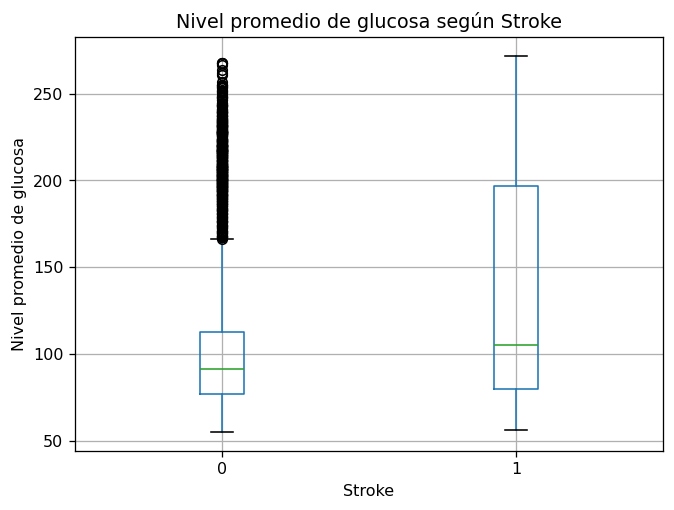

In [25]:
df.boxplot(column='avg_glucose_level', by='stroke')

plt.title('Nivel promedio de glucosa según Stroke')
plt.suptitle('')
plt.xlabel('Stroke')
plt.ylabel('Nivel promedio de glucosa')
plt.show()

### 5.4 Nivel promedio de glucosa según Stroke

El grupo con `stroke = 1` presenta una distribución del nivel promedio de glucosa más amplia y con valores centrales ligeramente superiores respecto al grupo con `stroke = 0`.

También se observan valores extremos en ambos grupos, los cuales se conservaron en esta etapa porque no se ha determinado que correspondan a errores.

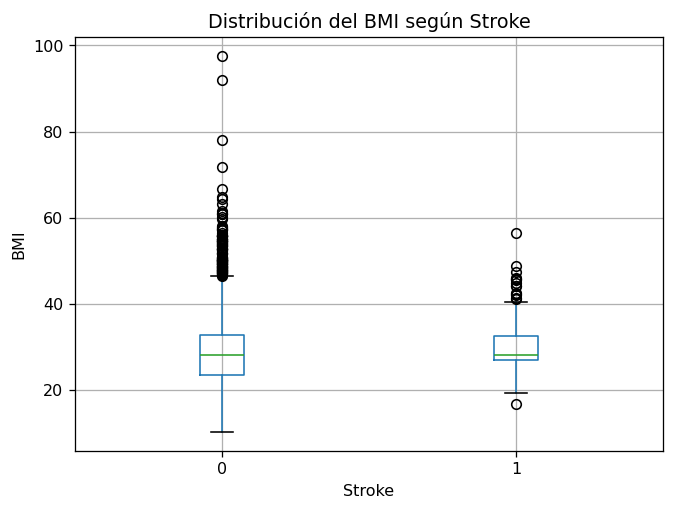

In [26]:
df.boxplot(column='bmi', by='stroke')

plt.title('Distribución del BMI según Stroke')
plt.suptitle('')
plt.xlabel('Stroke')
plt.ylabel('BMI')
plt.show()

### 5.5 Índice de masa corporal según Stroke

Las distribuciones de BMI entre ambos grupos son relativamente similares, aunque se observan algunos valores extremos.

Por esta razón, no se realizaron eliminaciones adicionales de estos registros durante la limpieza inicial.

### 5.6 Hipertensión y Stroke

Dentro del grupo sin hipertensión, aproximadamente el 3,97 % presentó stroke, mientras que entre las personas con hipertensión la proporción fue cercana al 13,25 %.

En este conjunto de datos, la proporción de casos de stroke es mayor entre las personas con hipertensión.

In [27]:
tabla_hipertension = pd.crosstab(
    df['hypertension'],
    df['stroke'],
    normalize='index'
) * 100

tabla_hipertension

stroke,0,1
hypertension,,
0,96.031230,3.968770
1,86.746988,13.253012


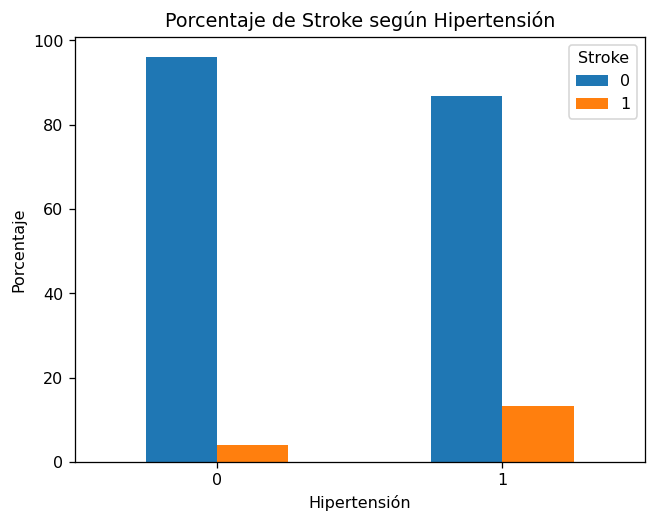

In [28]:
tabla_hipertension.plot(kind='bar')

plt.title('Porcentaje de Stroke según Hipertensión')
plt.xlabel('Hipertensión')
plt.ylabel('Porcentaje')
plt.xticks(rotation=0)
plt.legend(title='Stroke')
plt.show()

### 5.7 Enfermedad cardíaca y Stroke

Entre las personas sin enfermedad cardíaca, aproximadamente el 4,18 % presentó stroke. Entre quienes sí presentaban enfermedad cardíaca, la proporción fue cercana al 17,03 %.

Esta diferencia sugiere una asociación relevante dentro del conjunto de datos.

In [29]:
tabla_corazon = pd.crosstab(
    df['heart_disease'],
    df['stroke'],
    normalize='index'
) * 100

tabla_corazon

stroke,0,1
heart_disease,,
0,95.820401,4.179599
1,82.971014,17.028986


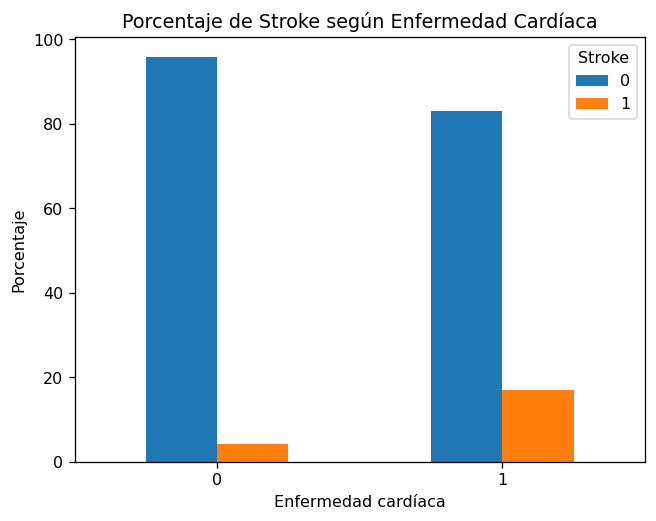

In [30]:
tabla_corazon.plot(kind='bar')

plt.title('Porcentaje de Stroke según Enfermedad Cardíaca')
plt.xlabel('Enfermedad cardíaca')
plt.ylabel('Porcentaje')
plt.xticks(rotation=0)
plt.legend(title='Stroke')
plt.show()

### 5.8 Estado de tabaquismo y Stroke

La mayor proporción de stroke se observó entre las personas clasificadas como `formerly smoked`, con aproximadamente 7,91 %.

Las demás categorías presentaron proporciones menores. La categoría `Unknown` fue conservada porque contiene una cantidad considerable de registros.

In [31]:
tabla_tabaco = pd.crosstab(
    df['smoking_status'],
    df['stroke'],
    normalize='index'
) * 100

tabla_tabaco

stroke,0,1
smoking_status,,
Unknown,96.955959,3.044041
formerly smoked,92.081448,7.918552
never smoked,95.243129,4.756871
smokes,94.676806,5.323194


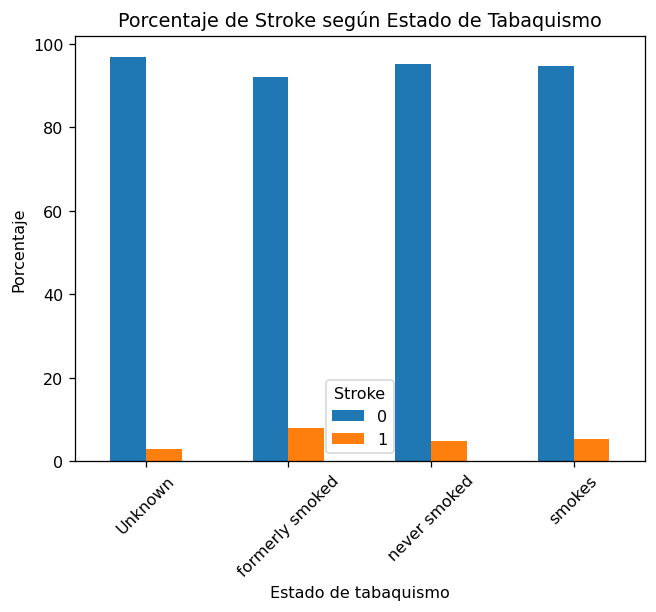

In [32]:
tabla_tabaco.plot(kind='bar')

plt.title('Porcentaje de Stroke según Estado de Tabaquismo')
plt.xlabel('Estado de tabaquismo')
plt.ylabel('Porcentaje')
plt.xticks(rotation=45)
plt.legend(title='Stroke')
plt.show()

### 5.9 Género y Stroke

La proporción de stroke fue aproximadamente de 4,71 % en mujeres y 5,11 % en hombres.

La diferencia entre ambos grupos es pequeña. La categoría `Other` no se consideró para análisis posteriores debido a que contenía un único registro.

In [33]:
tabla_genero = pd.crosstab(
    df['gender'],
    df['stroke'],
    normalize='index'
) * 100

tabla_genero

stroke,0,1
gender,,
Female,95.290581,4.709419
Male,94.893617,5.106383


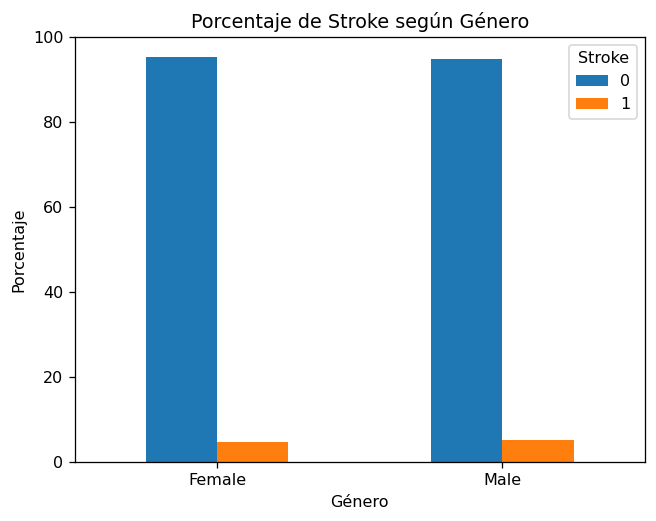

In [34]:
tabla_genero.plot(kind='bar')

plt.title('Porcentaje de Stroke según Género')
plt.xlabel('Género')
plt.ylabel('Porcentaje')
plt.xticks(rotation=0)
plt.legend(title='Stroke')
plt.show()

### 5.10 Estado civil y Stroke

Entre quienes indicaron no haber estado casados, aproximadamente el 1,65 % presentó stroke, mientras que entre quienes sí habían estado casados la proporción fue cercana al 6,56 %.

Esta diferencia debe interpretarse con cautela, ya que puede estar relacionada con otras variables como la edad.

In [35]:
tabla_casado = pd.crosstab(
    df['ever_married'],
    df['stroke'],
    normalize='index'
) * 100

tabla_casado

stroke,0,1
ever_married,,
No,98.348519,1.651481
Yes,93.438712,6.561288


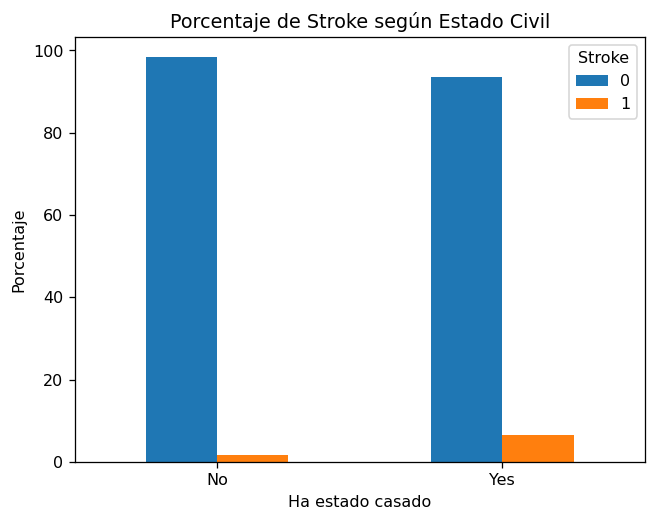

In [36]:
tabla_casado.plot(kind='bar')

plt.title('Porcentaje de Stroke según Estado Civil')
plt.xlabel('Ha estado casado')
plt.ylabel('Porcentaje')
plt.xticks(rotation=0)
plt.legend(title='Stroke')
plt.show()

### 5.11 Tipo de trabajo y Stroke

La categoría `Self-employed` presentó la mayor proporción de stroke, cercana al 7,94 %, seguida de los grupos `Private` y `Govt_job`.

Estas diferencias también pueden estar relacionadas con la distribución de la edad entre los distintos tipos de trabajo.

In [37]:
tabla_trabajo = pd.crosstab(
    df['work_type'],
    df['stroke'],
    normalize='index'
) * 100

tabla_trabajo

stroke,0,1
work_type,,
Govt_job,94.977169,5.022831
Never_worked,100.000000,0.000000
Private,94.904241,5.095759
Self-employed,92.063492,7.936508
children,99.708879,0.291121


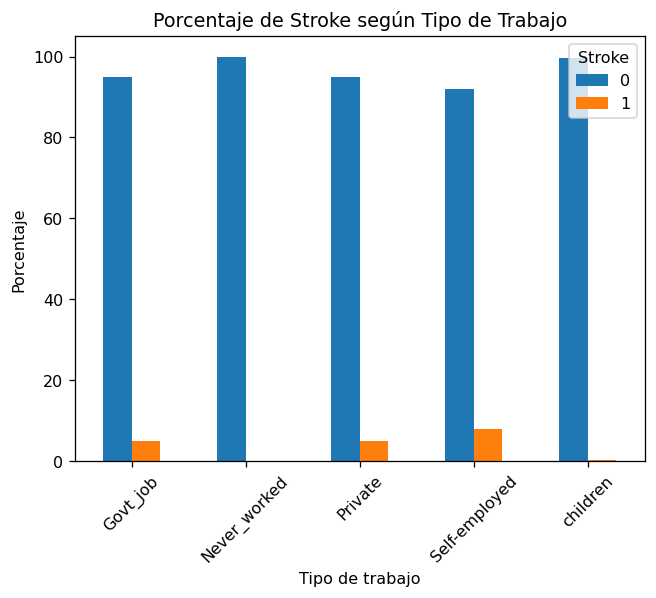

In [38]:
tabla_trabajo.plot(kind='bar')

plt.title('Porcentaje de Stroke según Tipo de Trabajo')
plt.xlabel('Tipo de trabajo')
plt.ylabel('Porcentaje')
plt.xticks(rotation=45)
plt.legend(title='Stroke')
plt.show()

### 5.12 Tipo de residencia y Stroke

La proporción de stroke fue aproximadamente de 4,53 % en personas con residencia rural y 5,20 % en personas con residencia urbana.

La diferencia entre ambos grupos es relativamente pequeña.

In [39]:
tabla_residencia = pd.crosstab(
    df['Residence_type'],
    df['stroke'],
    normalize='index'
) * 100

tabla_residencia

stroke,0,1
Residence_type,,
Rural,95.463589,4.536411
Urban,94.799692,5.200308


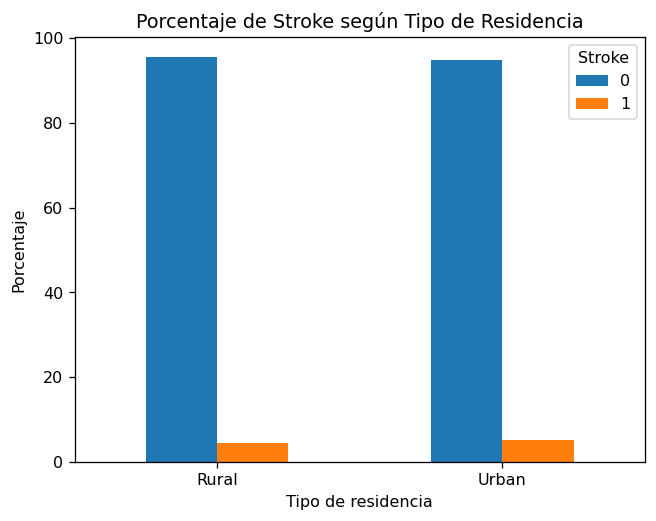

In [40]:
tabla_residencia.plot(kind='bar')

plt.title('Porcentaje de Stroke según Tipo de Residencia')
plt.xlabel('Tipo de residencia')
plt.ylabel('Porcentaje')
plt.xticks(rotation=0)
plt.legend(title='Stroke')
plt.show()

## 6. Bitácora de uso de Inteligencia Artificial

Durante el desarrollo de esta primera etapa del proyecto se utilizó **ChatGPT** como herramienta de apoyo para resolver dudas relacionadas con la organización del análisis, el uso de algunas instrucciones de Python y la interpretación inicial de los resultados obtenidos.

**Herramienta utilizada:** ChatGPT.

**Algunos prompts utilizados:**
- ¿Cómo puedo identificar los valores faltantes y duplicados del conjunto de datos en Python?
- ¿Qué tratamiento se puede aplicar a los valores faltantes de la variable `bmi`?
- ¿Cómo puedo representar gráficamente la relación entre las variables del dataset y la variable objetivo `stroke`?
- ¿Qué métricas deberían considerarse posteriormente teniendo en cuenta el desbalance de la variable objetivo?

**Propósito del uso de IA:** apoyar la comprensión de algunos comandos de Python, orientar la organización del notebook y facilitar la interpretación inicial de tablas y visualizaciones.

**Respuestas que resultaron útiles:** fueron útiles las orientaciones relacionadas con la identificación de valores faltantes, el análisis del desbalance de la variable `stroke`, la construcción de tablas porcentuales y la organización de las visualizaciones.

**Aspectos corregidos, validados o ajustados:** el grupo revisó los resultados obtenidos directamente en Google Colab antes de incorporarlos al proyecto. También se verificaron las cantidades de valores faltantes, registros duplicados, distribución de categorías y porcentajes de la variable objetivo. Las interpretaciones fueron ajustadas para no confundir asociaciones observadas en los datos con relaciones de causalidad.

**Decisiones tomadas por el grupo:** el grupo decidió utilizar un proyecto de clasificación, seleccionar la variable `stroke` como variable objetivo, imputar los valores faltantes de `bmi` mediante la mediana, eliminar la columna `id`, retirar el único registro perteneciente a la categoría `Other` de `gender` y conservar la categoría `Unknown` de `smoking_status` debido a la cantidad de registros que representa.

## 7. Conclusión inicial

La exploración inicial del conjunto de datos permitió conocer su estructura, identificar problemas de calidad y observar algunas relaciones preliminares entre las variables y la ocurrencia de accidente cerebrovascular.

El dataset original contenía 5.110 registros y 12 variables. Durante el diagnóstico se identificaron 201 valores faltantes en la variable `bmi`, ausencia de registros duplicados, una categoría poco frecuente en `gender` y un fuerte desbalance en la variable objetivo `stroke`, donde aproximadamente el 4,87 % de los registros corresponde a casos positivos.

Como parte de la limpieza inicial, los valores faltantes de `bmi` fueron imputados mediante la mediana, se eliminó el único registro perteneciente a la categoría `Other` de `gender` y se retiró la variable `id` por no aportar información útil para el análisis predictivo.

Las primeras visualizaciones mostraron diferencias importantes en variables como edad, hipertensión y enfermedad cardíaca. En particular, las personas con `stroke = 1` presentaron, en general, edades más altas, y la proporción de casos de stroke fue mayor entre las personas con hipertensión y enfermedad cardíaca.

Estos resultados constituyen una primera aproximación al comportamiento de los datos. En las siguientes etapas será necesario profundizar en el análisis exploratorio, estudiar las relaciones entre las variables, preparar los datos para el modelado y evaluar diferentes algoritmos de clasificación mediante métricas adecuadas, especialmente considerando el desbalance existente en la variable objetivo.

**Continuación:** las secciones siguientes desarrollan el EDA adicional y la evaluación de dos clasificadores exigida para el segundo avance.

---
# 8. Ampliación del EDA orientado a la clasificación

Se profundiza en el **desbalance de la variable objetivo**, medidas por clase, correlaciones numéricas y valores atípicos. Las asociaciones observadas no implican causalidad. `Unknown` en `smoking_status` se mantiene como categoría declarada y no como dato perdido.

In [41]:
# Los datos originales se reservan para modelar evitando imputación global
raw = pd.read_csv(ruta_csv)
assert raw.shape == (5110, 12), 'La estructura del dataset difiere de la utilizada en el primer corte.'
print('Faltantes originales por variable:\n', raw.isna().sum().sort_values(ascending=False))
print('\nDuplicados exactos:', raw.duplicated().sum())
print('\nDistribución de stroke en datos originales:\n',
      pd.DataFrame({'n':raw['stroke'].value_counts().sort_index(),
                    '%':(raw['stroke'].value_counts(normalize=True).sort_index()*100).round(2)}))
print('\nCasos con género Other:', (raw['gender']=='Other').sum())

Faltantes originales por variable:
 bmi                  201
id                     0
age                    0
gender                 0
hypertension           0
heart_disease          0
work_type              0
ever_married           0
Residence_type         0
avg_glucose_level      0
smoking_status         0
stroke                 0
dtype: int64

Duplicados exactos: 0

Distribución de stroke en datos originales:
            n      %
stroke             
0       4861  95.13
1        249   4.87

Casos con género Other: 1


age               avg_glucose_level                   bmi         \
       count   mean median             count    mean  median count   mean   
stroke                                                                      
0       4861  41.97   43.0              4861  104.80   91.47  4700  28.82   
1        249  67.73   71.0               249  132.54  105.22   209  30.47   

               
       median  
stroke         
0        28.0  
1        29.7

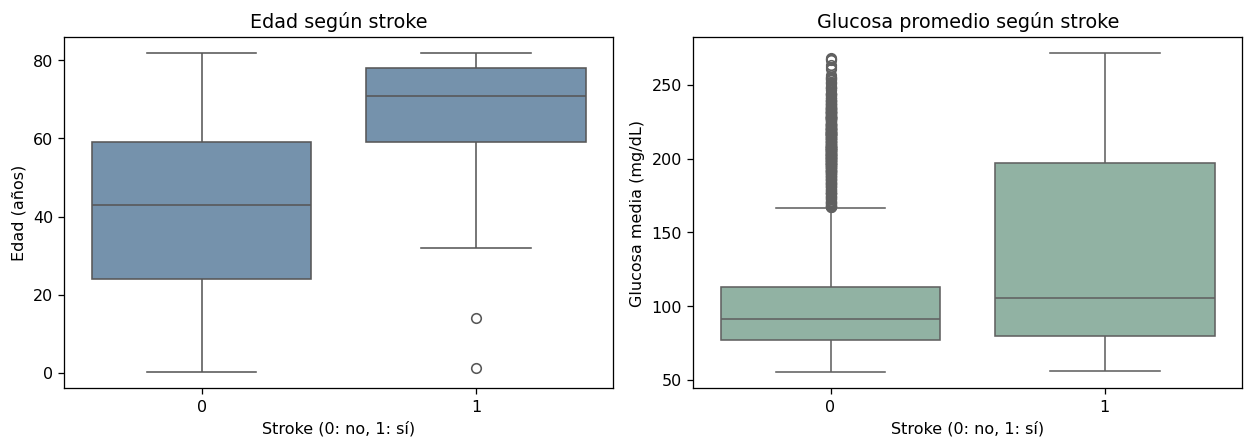

In [42]:
# Comparación descriptiva de variables clave por clase (sobre registros originales)
resumen_clases = raw.groupby('stroke')[['age', 'avg_glucose_level', 'bmi']].agg(['count','mean','median']).round(2)
display(resumen_clases)
fig, ax = plt.subplots(1, 2, figsize=(11,4))
sns.boxplot(data=raw, x='stroke', y='age', ax=ax[0], color='#6C93B5')
ax[0].set(title='Edad según stroke', xlabel='Stroke (0: no, 1: sí)', ylabel='Edad (años)')
sns.boxplot(data=raw, x='stroke', y='avg_glucose_level', ax=ax[1], color='#8CB7A4')
ax[1].set(title='Glucosa promedio según stroke', xlabel='Stroke (0: no, 1: sí)', ylabel='Glucosa media (mg/dL)')
plt.tight_layout(); plt.show()

**Interpretación:** la edad y la glucosa promedio presentan valores medios superiores entre registros con `stroke=1`. La distribución contiene valores extremos, pero no se eliminan indiscriminadamente, pues algunos pueden ser observaciones válidas. El BMI ausente no se muestra en las estadísticas disponibles, pero se conservará para imputarlo dentro del pipeline.

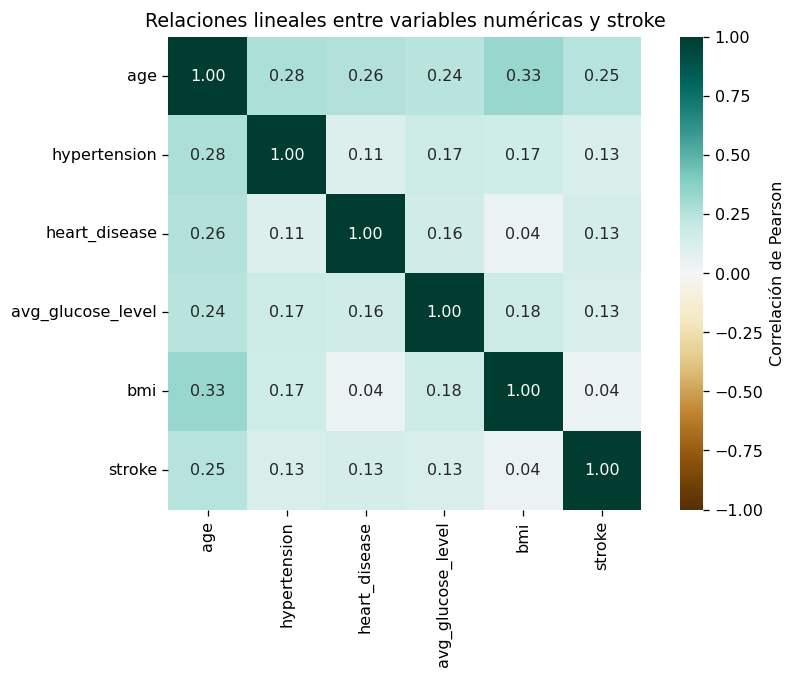

Correlaciones con stroke (descriptivas):
 stroke               1.000
age                  0.245
heart_disease        0.135
avg_glucose_level    0.132
hypertension         0.128
bmi                  0.042
Name: stroke, dtype: float64


In [43]:
# Matriz de correlación; stroke es binaria y la correlación no implica causalidad.
columnas_num = ['age','hypertension','heart_disease','avg_glucose_level','bmi','stroke']
matriz_corr = raw[columnas_num].corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='BrBG', center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={'label':'Correlación de Pearson'})
plt.title('Relaciones lineales entre variables numéricas y stroke')
plt.tight_layout(); plt.show()
print('Correlaciones con stroke (descriptivas):\n', matriz_corr['stroke'].sort_values(ascending=False).round(3))

**Interpretación:** las correlaciones de Pearson sintetizan asociaciones lineales, no determinan importancia predictiva definitiva. La comparación entre variables como `age`, `hypertension` y `heart_disease` complementa las tablas por categoría mostradas en el primer corte; no se interpretan como relaciones de causa-efecto.

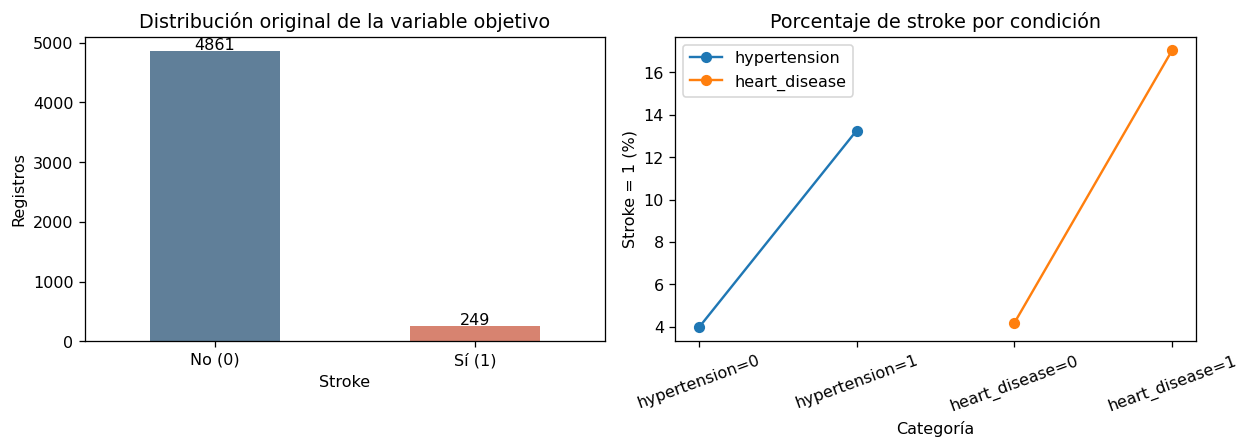

Hipertensión, % stroke = 1: {0: 3.97, 1: 13.25}
Enfermedad cardíaca, % stroke = 1: {0: 4.18, 1: 17.03}


In [44]:
# Frecuencias y proporciones por categoría (denominador: registros de cada categoría)
fig, ax = plt.subplots(1,2,figsize=(11,4))
(raw['stroke'].value_counts().sort_index()).plot.bar(ax=ax[0],color=['#607F99','#D78370'])
ax[0].set(title='Distribución original de la variable objetivo',xlabel='Stroke',ylabel='Registros')
ax[0].set_xticklabels(['No (0)','Sí (1)'],rotation=0)
for i,val in enumerate(raw['stroke'].value_counts().sort_index()): ax[0].text(i,val+25,str(val),ha='center')
for var in ['hypertension','heart_disease']:
    tabla = (pd.crosstab(raw[var],raw['stroke'],normalize='index')*100)[1]
    ax[1].plot([f'{var}={indice}' for indice in tabla.index],tabla.values,marker='o',label=var)
ax[1].set(title='Porcentaje de stroke por condición',xlabel='Categoría',ylabel='Stroke = 1 (%)')
ax[1].tick_params(axis='x',rotation=20)
ax[1].legend();plt.tight_layout();plt.show()
print('Hipertensión, % stroke = 1:',(pd.crosstab(raw.hypertension,raw.stroke,normalize='index')[1]*100).round(2).to_dict())
print('Enfermedad cardíaca, % stroke = 1:',(pd.crosstab(raw.heart_disease,raw.stroke,normalize='index')[1]*100).round(2).to_dict())

**Interpretación:** hay fuerte desbalance entre clases: el 4,87 % presenta `stroke=1`. También se observan diferentes proporciones de registros positivos según antecedentes clínicos. Estas diferencias podrían depender de otras variables no controladas, como edad. Se necesitan métricas específicas para la clase positiva.

---
# 9. Preparación reproducible para modelado

Se compara **regresión logística** (modelo lineal de clasificación) frente a un **árbol de decisión** (reglas no lineales). La variable objetivo es `stroke`. Se excluye `id` por ser identificador y la única fila con `gender='Other'` para conservar el criterio del primer avance. Se mantienen las restantes características. La separación entrenamiento/prueba es **80/20 estratificada** (`random_state=42`). Las imputaciones, el escalado y la codificación categórica se ajustan **solo al entrenamiento**, dentro de cada `Pipeline`.

In [45]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             roc_auc_score, average_precision_score,
                             PrecisionRecallDisplay, RocCurveDisplay, ConfusionMatrixDisplay)

# Recargar antes de modelar: no se usa df, cuyo BMI ya fue imputado para EDA.
datos_modelos = pd.read_csv(ruta_csv)
datos_modelos = datos_modelos[datos_modelos['gender']!='Other'].copy()
X = datos_modelos.drop(columns=['id', 'stroke'])
y = datos_modelos['stroke'].astype(int)
numericas = X.select_dtypes(include=np.number).columns.tolist()
categoricas = X.select_dtypes(exclude=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print('Registros analizados:',len(datos_modelos),'Predictores:',X.shape[1])
print('Numéricas:',numericas, '\nCategóricas:',categoricas)
print('Entrenamiento:',len(y_train),y_train.value_counts().to_dict())
print('Prueba:',len(y_test),y_test.value_counts().to_dict())

Registros analizados: 5109 Predictores: 10
Numéricas: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi'] 
Categóricas: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
Entrenamiento: 4087 {0: 3888, 1: 199}
Prueba: 1022 {0: 972, 1: 50}


In [46]:
preprocesamiento = ColumnTransformer(transformers=[
    ('num', Pipeline(steps=[('imputacion', SimpleImputer(strategy='median')),
                             ('escala', StandardScaler())]), numericas),
    ('cat', Pipeline(steps=[('imputacion', SimpleImputer(strategy='most_frequent')),
                             ('one_hot', OneHotEncoder(handle_unknown='ignore'))]), categoricas)
])
modelos = {
    'Regresión logística': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
    'Árbol de decisión': DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                                                class_weight='balanced', random_state=42)
}
# class_weight='balanced' reduce el sesgo hacia la clase mayoritaria.
# No se realiza optimización de hiperparámetros en esta entrega.
pipelines = {nombre: Pipeline(steps=[('preprocesamiento',preprocesamiento),
                                        ('clasificador',modelo)])
             for nombre, modelo in modelos.items()}
for nombre, pipeline in pipelines.items():
    pipeline.fit(X_train,y_train)
    print('Modelo entrenado:',nombre)

Modelo entrenado: Regresión logística


Modelo entrenado: Árbol de decisión


---
# 10. Evaluación en datos de prueba

Se informa **accuracy, precision, recall, F1-score, ROC-AUC y PR-AUC** (average precision), además de resultados por clase y matriz de confusión. La clase **1 (accidente cerebrovascular)** es prioritaria: un falso negativo significa que un registro positivo fue clasificado como negativo, mientras que un falso positivo es una alerta incorrecta. Debido al desbalance, también se calcula una línea base que predice siempre clase 0, para mostrar por qué un accuracy alto no es suficiente.

In [47]:
# Línea base explícita; no es un tercer modelo propuesto, sirve como control.
baseline = DummyClassifier(strategy='most_frequent', random_state=42)
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)
print('Baseline mayoritaria:', {'accuracy':round(accuracy_score(y_test,base_pred),4),
                              'recall_stroke':round(recall_score(y_test,base_pred),4),
                              'f1_stroke':round(f1_score(y_test,base_pred,zero_division=0),4)})

metricas, predicciones, probabilidades = [], {}, {}
for nombre,pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:,1]
    predicciones[nombre],probabilidades[nombre]=y_pred,y_prob
    metricas.append({'Modelo':nombre,
                     'Accuracy':accuracy_score(y_test,y_pred),
                     'Precision (stroke=1)':precision_score(y_test,y_pred,zero_division=0),
                     'Recall (stroke=1)':recall_score(y_test,y_pred,zero_division=0),
                     'F1 (stroke=1)':f1_score(y_test,y_pred,zero_division=0),
                     'ROC-AUC':roc_auc_score(y_test,y_prob),
                     'PR-AUC':average_precision_score(y_test,y_prob)})
resultados = pd.DataFrame(metricas).set_index('Modelo')
display(resultados.round(4))

Baseline mayoritaria: {'accuracy': 0.9511, 'recall_stroke': 0.0, 'f1_stroke': 0.0}


,Accuracy,Precision (stroke=1),Recall (stroke=1),F1 (stroke=1),ROC-AUC,PR-AUC
Modelo,,,,,,
Regresión logística,0.7378,0.1342,0.8,0.2299,0.8393,0.2594
Árbol de decisión,0.7133,0.1238,0.8,0.2145,0.8062,0.1727



 Regresión logística
Matriz de confusión [filas: reales 0,1; columnas: predichas 0,1]:
[[714 258]
 [ 10  40]]
                precision    recall  f1-score   support

Sin stroke (0)      0.986     0.735     0.842       972
Con stroke (1)      0.134     0.800     0.230        50

      accuracy                          0.738      1022
     macro avg      0.560     0.767     0.536      1022
  weighted avg      0.945     0.738     0.812      1022


 Árbol de decisión
Matriz de confusión [filas: reales 0,1; columnas: predichas 0,1]:
[[689 283]
 [ 10  40]]
                precision    recall  f1-score   support

Sin stroke (0)      0.986     0.709     0.825       972
Con stroke (1)      0.124     0.800     0.214        50

      accuracy                          0.713      1022
     macro avg      0.555     0.754     0.520      1022
  weighted avg      0.944     0.713     0.795      1022



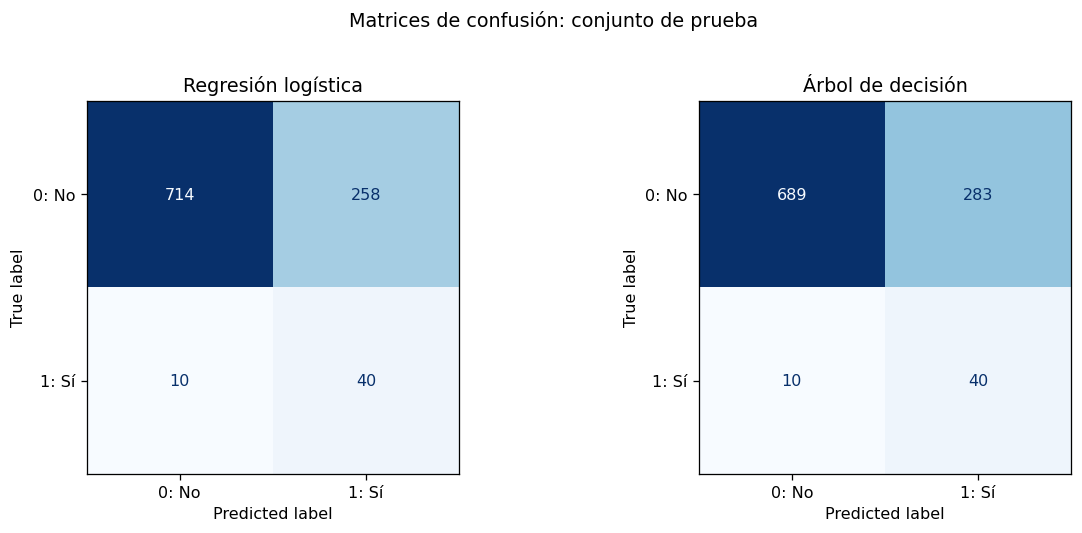

In [48]:
for nombre,pred in predicciones.items():
    print('\n'+'='*70+'\n',nombre)
    print('Matriz de confusión [filas: reales 0,1; columnas: predichas 0,1]:')
    print(confusion_matrix(y_test,pred))
    print(classification_report(y_test,pred,target_names=['Sin stroke (0)','Con stroke (1)'],digits=3,zero_division=0))
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
for ax,(nombre,pred) in zip(axes,predicciones.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test,pred),display_labels=['0: No','1: Sí']).plot(
        ax=ax,cmap='Blues',colorbar=False,values_format='d')
    ax.set_title(nombre)
plt.suptitle('Matrices de confusión: conjunto de prueba', y=1.02)
plt.tight_layout();plt.show()

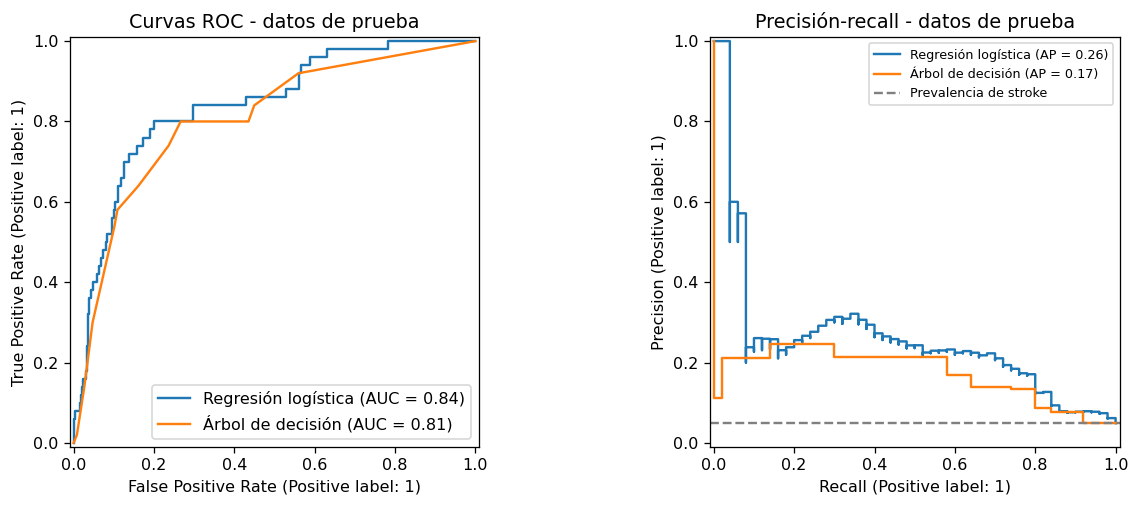

In [49]:
fig,axes=plt.subplots(1,2,figsize=(11.5,4.5))
for nombre in pipelines:
    RocCurveDisplay.from_predictions(y_test,probabilidades[nombre],name=nombre,ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test,probabilidades[nombre],name=nombre,ax=axes[1])
axes[0].set(title='Curvas ROC - datos de prueba')
axes[1].set(title='Precisión-recall - datos de prueba')
axes[1].axhline(y=y_test.mean(),ls='--',c='gray',label='Prevalencia de stroke')
axes[1].legend(loc='upper right', fontsize=8)
plt.tight_layout();plt.show()

**Interpretación:** en clases muy desbalanceadas, la precisión de la clase positiva puede ser baja aunque el recall sea alto. Debe informarse el costo de los falsos positivos y negativos. ROC-AUC y, especialmente, PR-AUC complementan la evaluación sin sustituir la matriz de confusión; ninguno de los resultados constituye validación clínica.

---
# 11. Comparación adicional por validación cruzada

Para contrastar la estabilidad de los modelos, se realiza validación cruzada **estratificada de cinco pliegues exclusivamente sobre los datos de entrenamiento**; el conjunto de prueba continúa reservado. Se informan promedios y desviaciones estándar de F1, recall y PR-AUC de la clase positiva.

In [50]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
registros_cv=[]
for nombre,pipeline in pipelines.items():
    evaluacion = cross_validate(pipeline, X_train, y_train, cv=cv,
        scoring={'F1':'f1','Recall':'recall','PR_AUC':'average_precision'},
        n_jobs=1, error_score='raise')
    registros_cv.append({'Modelo':nombre,
       'F1 CV (media)':evaluacion['test_F1'].mean(),
       'F1 CV (desv.)':evaluacion['test_F1'].std(),
       'Recall CV (media)':evaluacion['test_Recall'].mean(),
       'PR-AUC CV (media)':evaluacion['test_PR_AUC'].mean()})
resultados_cv = pd.DataFrame(registros_cv).set_index('Modelo')
display(resultados_cv.round(4))

,F1 CV (media),F1 CV (desv.),Recall CV (media),PR-AUC CV (media)
Modelo,,,,
Regresión logística,0.2372,0.0183,0.8191,0.1920
Árbol de decisión,0.1998,0.0227,0.7341,0.1365


---
# 12. Interpretación de variables y limitaciones

Importancias predictivas del árbol (no causales):


,Importancia
num__age,0.8558
num__avg_glucose_level,0.0853
num__bmi,0.0332
cat__smoking_status_never smoked,0.0170
cat__smoking_status_formerly smoked,0.0074
cat__gender_Male,0.0012
num__heart_disease,0.0000
num__hypertension,0.0000
cat__ever_married_Yes,0.0000
cat__work_type_Govt_job,0.0000


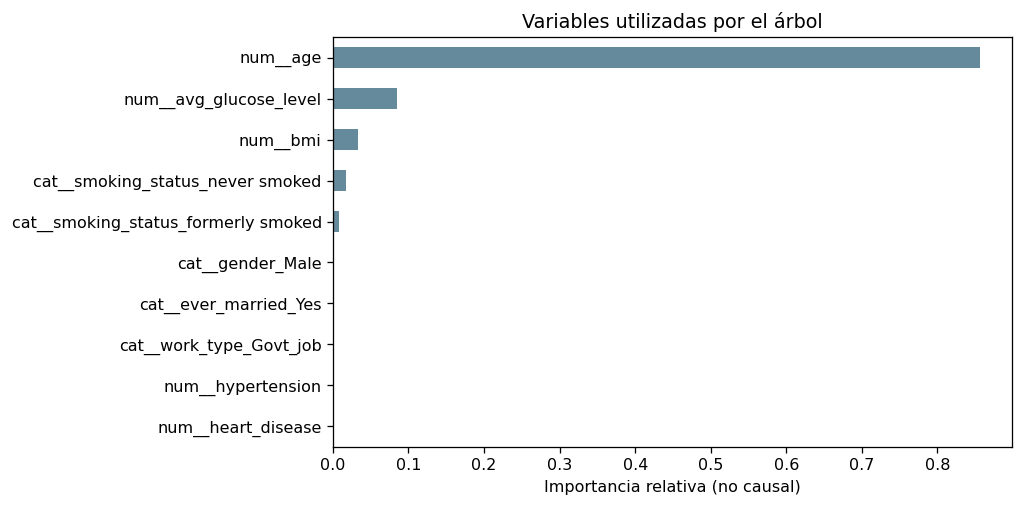

In [51]:
# El árbol permite describir qué variables se utilizan en los cortes.
arbol=pipelines['Árbol de decisión']
nombres_transformados=arbol.named_steps['preprocesamiento'].get_feature_names_out()
importancia = pd.Series(arbol.named_steps['clasificador'].feature_importances_,
                        index=nombres_transformados).sort_values(ascending=False)
print('Importancias predictivas del árbol (no causales):')
display(importancia.head(12).to_frame('Importancia').round(4))
ax=importancia.head(10).sort_values().plot.barh(figsize=(9,4.5),color='#658A9B')
ax.set(title='Variables utilizadas por el árbol',xlabel='Importancia relativa (no causal)',ylabel='')
plt.tight_layout();plt.show()

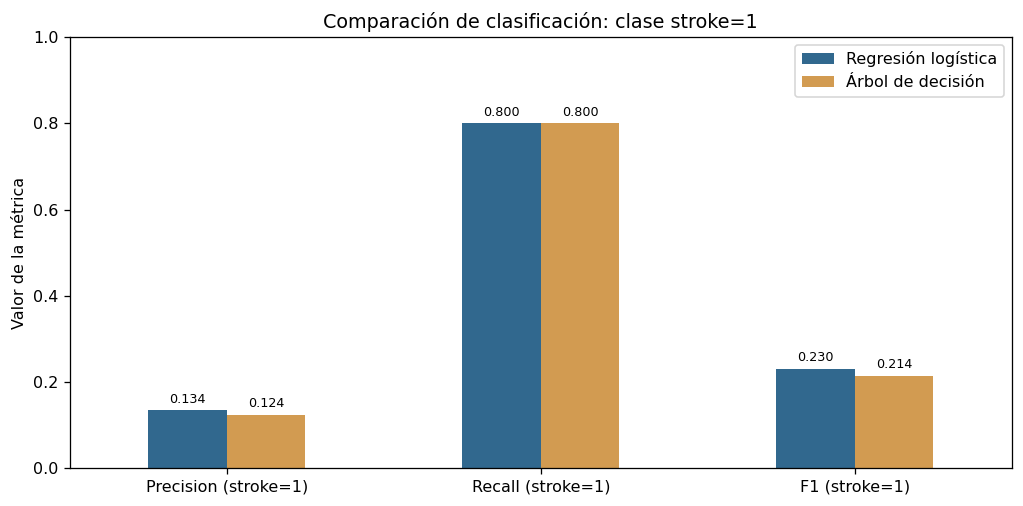

In [52]:
# Comparación de modelos en las métricas de la clase minoritaria
comparar=resultados[['Precision (stroke=1)','Recall (stroke=1)','F1 (stroke=1)']].T
ax=comparar.plot.bar(figsize=(9,4.5),ylim=(0,1),color=['#31688E','#D29B51'])
ax.set(title='Comparación de clasificación: clase stroke=1',ylabel='Valor de la métrica',xlabel='')
ax.tick_params(axis='x',rotation=0)
for cont in ax.containers: ax.bar_label(cont,fmt='%.3f',padding=3,fontsize=8)
plt.legend(loc='upper right');plt.tight_layout();plt.show()

**Limitaciones:** 1) la proporción de registros positivos es reducida; 2) esta evaluación usa una única partición de prueba (complementada con validación cruzada interna); 3) el conjunto de datos es observacional y no se ha validado clínicamente ni externamente; 4) los valores de `smoking_status='Unknown'` no deben reinterpretarse como personas no fumadoras; 5) ni la importancia de variables del árbol ni las correlaciones indican causalidad. La configuración `class_weight='balanced'` suele mejorar sensibilidad a costa de falsas alarmas; las probabilidades deben calibrarse y verificarse externamente antes de cualquier aplicación fuera del aula.

---
# 13. Conclusiones preliminares del segundo corte

In [53]:
mejor_f1=resultados['F1 (stroke=1)'].idxmax()
print('Principales hallazgos del EDA:')
print(f'- El dataset original contiene {len(raw)} registros; {raw.stroke.sum()} positivos ({raw.stroke.mean():.2%}).')
print('- La edad media de la clase 1 es {:.2f} años frente a {:.2f} en la clase 0.'.format(
    *[raw.loc[raw.stroke==i,'age'].mean() for i in [1,0]]))
print('- Las proporciones de stroke son distintas según hipertensión y enfermedad cardíaca; no prueban causalidad.')
print('\nComparación de modelos:')
for modelo in resultados.index:
    r=resultados.loc[modelo]
    mat=confusion_matrix(y_test,predicciones[modelo])
    print(f'- {modelo}: F1 stroke=1 {r["F1 (stroke=1)"]:.3f}, recall {r["Recall (stroke=1)"]:.3f}, precisión {r["Precision (stroke=1)"]:.3f}, ROC-AUC {r["ROC-AUC"]:.3f}; FN={mat[1,0]}, FP={mat[0,1]}.')
print(f'El mayor F1 para stroke=1 en la prueba corresponde a: {mejor_f1}.')
print('Esta selección es preliminar. Las falsas alarmas, el desbalance y la falta de validación externa impiden su uso clínico.')

Principales hallazgos del EDA:
- El dataset original contiene 5110 registros; 249 positivos (4.87%).
- La edad media de la clase 1 es 67.73 años frente a 41.97 en la clase 0.
- Las proporciones de stroke son distintas según hipertensión y enfermedad cardíaca; no prueban causalidad.

Comparación de modelos:
- Regresión logística: F1 stroke=1 0.230, recall 0.800, precisión 0.134, ROC-AUC 0.839; FN=10, FP=258.
- Árbol de decisión: F1 stroke=1 0.214, recall 0.800, precisión 0.124, ROC-AUC 0.806; FN=10, FP=283.
El mayor F1 para stroke=1 en la prueba corresponde a: Regresión logística.
Esta selección es preliminar. Las falsas alarmas, el desbalance y la falta de validación externa impiden su uso clínico.


---
# 14. Declaración y evaluación crítica del uso de IA

**Herramienta:** ChatGPT (OpenAI). **Propósito:** revisar código, ampliar EDA, organizar pipelines, interpretar métricas y ayudar con la redacción del segundo informe.

**Solicitudes principales en la conversación de trabajo:** el usuario compartió el enunciado «Avance proyecto 2» junto con «me piden hacer lo siguiente»; posteriormente envió el primer informe con «esete fue lo que trabaje a principio», el notebook con «este fue codigo qué se trabajo» y el CSV original. El enunciado completo debe conservarse como anexo o registro del grupo si se solicita el texto íntegro del prompt.

**Problemas identificados y correcciones:** el notebook del primer corte dependía de `files.upload()` de Google Colab y de un nombre de archivo fijo; se sustituyó por lectura portable. La imputación original de `bmi` sobre todos los registros se mantuvo únicamente para el EDA inicial; para la evaluación de modelos se recarga el CSV y se realiza imputación ajustada al entrenamiento. Se evitó confundir accuracy con capacidad de identificar `stroke=1` y se separaron modelos de otro ejercicio con un dataset distinto.

**Validación requerida por el grupo:** volver a ejecutar el notebook con el CSV entregado; comparar todos los números y tablas contra el PDF; inspeccionar figuras y citas; revisar decisiones de limpieza y uso de `class_weight`; y comprender las métricas antes de entregar. Los resultados son ilustrativos y no indican eficacia diagnóstica en población real.

**Responsabilidad académica:** los integrantes son responsables de revisar, corregir y aprobar el producto final. Este texto es una propuesta de declaración para confirmar y ajustar según su trabajo efectivo.